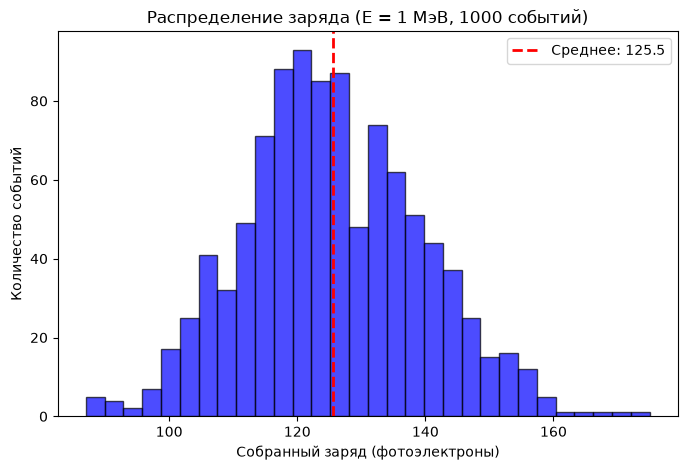

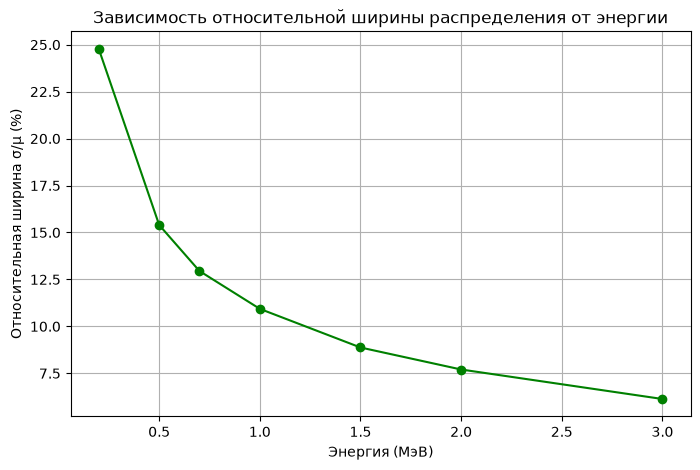

В центре (z=0):     125.5
Смещен (z=1 м):     124.9
Разница:            0.6 (0.45%)


In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


class PMT:
    def __init__(self, position, r, a):
        self.position = np.array(position)
        self.r = r
        self.a = a

    def get_photoelectrons(self, num_photons):
        if num_photons == 0: return 0
        return np.random.poisson(self.a * num_photons)

class Detector:
    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R, self.N, self.r, self.a = R, N, r, a
        self.pmts = self._generate_pmt_fibonacci()

    def _generate_pmt_fibonacci(self):
        pmts = []
        indices = np.arange(0, self.N, dtype=float) + 0.5
        phi = np.arccos(1 - 2 * indices / self.N)
        theta = np.pi * (1 + 5**0.5) * indices
        x = np.cos(theta) * np.sin(phi) * self.R
        y = np.sin(theta) * np.sin(phi) * self.R
        z = np.cos(phi) * self.R
        for i in range(self.N):
            pmts.append(PMT([x[i], y[i], z[i]], self.r, self.a))
        return pmts

    def simulate_event(self, E, source_z=0.0, Y=10000):
        N_photons = int(Y * E)
        source_pos = np.array([0.0, 0.0, source_z])

        directions = np.random.normal(size=(N_photons, 3))
        directions /= np.linalg.norm(directions, axis=1, keepdims=True)
        

        B = 2 * np.dot(directions, source_pos)
        C = np.dot(source_pos, source_pos) - self.R**2
        t = (-B + np.sqrt(B**2 - 4*C)) / 2
        
        hit_points = source_pos + t[:, np.newaxis] * directions
        
        total_charge = 0
        for pmt in self.pmts:
            dists = np.linalg.norm(hit_points - pmt.position, axis=1)
            hits = np.sum(dists <= pmt.r)
            total_charge += pmt.get_photoelectrons(hits)
            
        return total_charge


np.random.seed(4)
detector = Detector(R=2.0, N=40, r=0.1, a=0.5)


charges_1MeV = [detector.simulate_event(E=1.0) for _ in range(1000)]

plt.figure(figsize=(8, 5))
plt.hist(charges_1MeV, bins=30, alpha=0.7, color='blue', edgecolor='black')
plt.title('Распределение заряда (E = 1 МэВ, 1000 событий)')
plt.xlabel('Собранный заряд (фотоэлектроны)')
plt.ylabel('Количество событий')
plt.axvline(np.mean(charges_1MeV), color='red', linestyle='dashed', linewidth=2, label=f'Среднее: {np.mean(charges_1MeV):.1f}')
plt.legend()
plt.show()


energies = [0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0]
rel_widths = []

for E in energies:
    sim_data = [detector.simulate_event(E=E) for _ in range(1000)]
    mean = np.mean(sim_data)
    std = np.std(sim_data)
    rel_widths.append(std / mean) 

plt.figure(figsize=(8, 5))
plt.plot(energies, np.array(rel_widths) * 100, marker='o', linestyle='-', color='green')
plt.title('Зависимость относительной ширины распределения от энергии')
plt.xlabel('Энергия (МэВ)')
plt.ylabel('Относительная ширина σ/μ (%)')
plt.grid(True)
plt.show()


charges_shifted = [detector.simulate_event(E=1.0, source_z=1.0) for _ in range(1000)]
mean_center = np.mean(charges_1MeV)
mean_shifted = np.mean(charges_shifted)

print(f"В центре (z=0):     {mean_center:.1f}")
print(f"Смещен (z=1 м):     {mean_shifted:.1f}")
print(f"Разница:            {abs(mean_shifted - mean_center):.1f} ({abs(mean_shifted - mean_center)/mean_center*100:.2f}%)")